# 00. Business Context and Problem Framing

**Procurement Intelligence Platform** | Notebook 00 of 13

Why a port and energy-services company needs to see its procurement pipeline weeks ahead, and how this project answers that.

| | |
|---|---|
| **Inputs** | Company scenario (fictional), stakeholder interviews (summarised) |
| **Outputs** | Problem statement, business questions, success metrics, project map |
| **Skills shown** | Problem framing, stakeholder thinking, analytics strategy |

> **Data disclaimer.** Quayline Offshore Logistics, its suppliers, people and figures are fictional. The dataset is produced by a
> documented simulator (notebook 01) that reproduces the behaviour of a real procure-to-pay process. No real company data is used.

## 1. The company

**Quayline Offshore Logistics** runs a deep-water port base for the offshore energy industry. Four business units keep it moving:

| Business unit | What it does | Typical spare parts |
|---|---|---|
| Port Operations | Cranes, reach stackers, quay infrastructure | Hydraulics, wire ropes, bearings |
| Fleet and Workshop | 60 light vehicles, heavy trucks, forklifts | Filters, tyres, engine parts |
| Power Generation | Gas generators, low-voltage and HV networks | Electrical components, controls |
| Marine Services | Tugboats supporting vessel berthing | Engine-room parts, deck and safety gear |

About half of the spare parts are **imported**. A foreign purchase order takes around four months from request to receipt, a local one
about six weeks. Every purchase goes through the same pipeline:

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from p2p.viz.theme import use_matplotlib, BRAND, SERIES, ORIGIN_COLORS, STATUS, shade_shocks
use_matplotlib()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

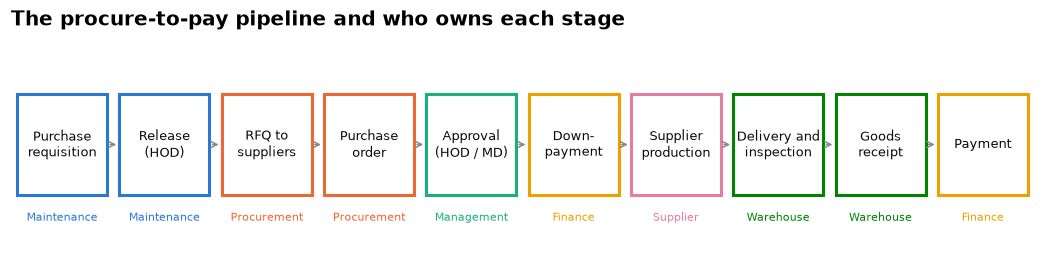

In [2]:
from p2p.data import query

stages = ["Purchase\nrequisition", "Release\n(HOD)", "RFQ to\nsuppliers", "Purchase\norder", "Approval\n(HOD / MD)",
          "Down-\npayment", "Supplier\nproduction", "Delivery and\ninspection", "Goods\nreceipt", "Payment"]
owners = ["Maintenance", "Maintenance", "Procurement", "Procurement", "Management", "Finance", "Supplier", "Warehouse", "Warehouse", "Finance"]

fig, ax = plt.subplots(figsize=(12, 2.4))
ax.set_xlim(0, len(stages)); ax.set_ylim(0, 1.25); ax.axis("off")
owner_color = {o: c for o, c in zip(dict.fromkeys(owners), SERIES)}
for i, (s, o) in enumerate(zip(stages, owners)):
    ax.add_patch(plt.Rectangle((i + 0.06, 0.32), 0.88, 0.62, facecolor="white", edgecolor=owner_color[o], lw=2))
    ax.text(i + 0.5, 0.63, s, ha="center", va="center", fontsize=8.5, color=BRAND["ink"])
    ax.text(i + 0.5, 0.18, o, ha="center", va="center", fontsize=7.5, color=owner_color[o])
    if i < len(stages) - 1:
        ax.annotate("", xy=(i + 1.06, 0.63), xytext=(i + 0.94, 0.63), arrowprops=dict(arrowstyle="->", color=BRAND["muted"]))
ax.set_title("The procure-to-pay pipeline and who owns each stage")
plt.show()

Six departments touch every requisition. Each one sees only its own step, so **nobody sees the whole pipeline**. That is the root
problem this project addresses.

## 2. The problem, in the words of the stakeholders

| Stakeholder | What they told us | What they need |
|---|---|---|
| **Head of Maintenance** | "A tug waits weeks for an engine part and nobody can tell me when it arrives." | A reliable arrival date (with a range) for every critical part |
| **Head of Procurement** | "The backlog keeps growing and I find out at month end." | Early warning: how big the backlog will be in 4, 8 and 12 weeks |
| **Finance Controller** | "Downpayments surprise us. I cannot plan foreign currency." | A weekly cash-out forecast with a risk range |
| **Managing Director** | "If I approve faster or move spend to local suppliers, what do we actually gain?" | What-if analysis before taking decisions |
| **Planning team** | "We have SAP, but every report is a manual Excel." | One trusted set of KPIs, automated |

In [3]:
sections = query("""
    select s.business_unit, s.section_name,
           count(*)                                        as requisition_lines,
           round(sum(f.line_value_usd) / 1e6, 2)           as value_musd,
           round(avg((f.supplier_origin = 'Foreign')::int), 2) as foreign_share
    from marts.fct_requisition_line f join marts.dim_section s using (section_id)
    where f.pr_created_on >= '2022-01-03'
    group by all order by 1, 3 desc
""")
display(sections)
print(f"Requisition lines 2022-2025: {sections.requisition_lines.sum():,} | value: USD {sections.value_musd.sum():,.1f} million")

,business_unit,section_name,requisition_lines,value_musd,foreign_share
0,Fleet and Workshop,Light Vehicles,4255,7.800,0.250
1,Fleet and Workshop,Heavy Duty Trucks,3355,6.940,0.370
2,Fleet and Workshop,Minor Equipment,1959,2.500,0.360
3,Marine Services,Tugboats,2393,4.220,0.520
4,Marine Services,Engine Room,2019,6.550,0.670
5,Marine Services,Deck and Safety,1754,4.660,0.430
6,Port Operations,Cranes and Lifting,3638,10.180,0.450
7,Port Operations,Reach Stackers,2970,4.150,0.660
8,Port Operations,Port Infrastructure,1786,2.680,0.140
9,Power Generation,Low Voltage Electrical,3154,5.270,0.290


Requisition lines 2022-2025: 31,289 | value: USD 67.8 million


**What we see.** Four years, about 31,000 requisition lines and USD 68 million of spend spread over 12 sections. Fleet and Workshop raises
the most lines. HV Switchgear, Engine Room, Reach Stackers and Generators depend most on imports (60 to 76 percent of lines).

**Why it matters.** Foreign-dependent sections are where long and uncertain lead times hit hardest, so forecasting and expediting
effort should be focused there.

## 3. The events that shaped the period

The last four years were not calm. These events are part of the data and every model is tested on whether it copes with them:

,Name,Start,End,Description
0,FX liquidity crisis,2023-06-05,2024-03-31,Local currency devalues about 55%; foreign downpayments wait for FX allocation.
1,Approval policy change,2024-04-01,2025-12-31,New delegation of authority: MD threshold raised from USD 5k to 25k and e-approvals.
2,Port congestion,2024-09-02,2024-10-13,Six weeks of congestion at the import port; foreign deliveries are held.
3,New marine contract,2025-03-03,2025-12-31,Two additional tug vessels under contract; Marine demand steps up about 25%.
4,Key supplier suspension,2025-06-02,2025-07-27,A top foreign marine supplier suspends shipments for eight weeks.


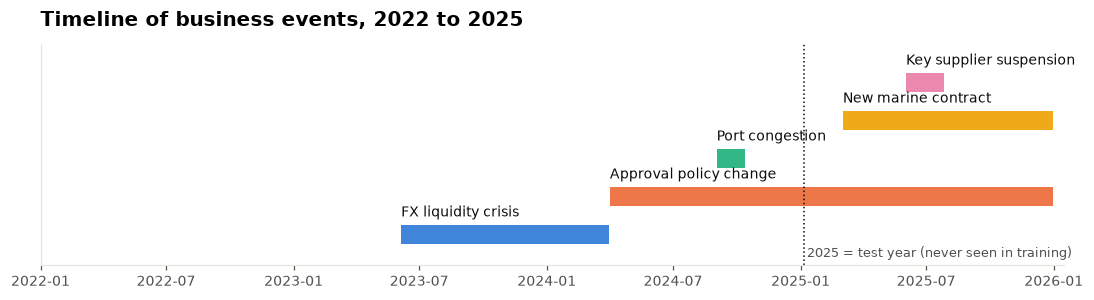

In [4]:
from p2p.config import CFG
ev = pd.DataFrame([s.__dict__ for s in CFG.shocks])
display(ev.rename(columns=str.title))

fig, ax = plt.subplots(figsize=(12, 2.6))
for i, s in enumerate(CFG.shocks):
    a, b = pd.Timestamp(s.start), pd.Timestamp(s.end)
    ax.barh(i, (b - a).days, left=a, height=0.5, color=SERIES[i], alpha=0.9)
    ax.text(a, i + 0.38, s.name, fontsize=9, color=BRAND["ink"], va="bottom")
ax.set_yticks([]); ax.set_xlim(pd.Timestamp("2022-01-01"), pd.Timestamp("2026-01-15"))
ax.axvline(pd.Timestamp("2025-01-06"), color=BRAND["ink"], lw=1, ls=":")
ax.text(pd.Timestamp("2025-01-10"), -0.6, "2025 = test year (never seen in training)", fontsize=8.5, color=BRAND["ink_2"])
ax.set_ylim(-0.8, len(CFG.shocks)); ax.grid(axis="y", visible=False); ax.set_title("Timeline of business events, 2022 to 2025")
plt.show()

## 4. Business questions and how we will answer them

| # | Business question | Analytical approach | Notebook |
|---|---|---|---|
| Q1 | How many requisition lines will each section raise in the next 12 weeks? | Time-series arena: baselines, ETS, SARIMAX, Theta, Croston, Prophet, LightGBM, XGBoost, Random Forest, N-HiTS, N-BEATS, Chronos, Monte Carlo | 07 to 11 |
| Q2 | How big will the open backlog be, and how much cash goes out? | Process Monte Carlo against statistical models | 10, 11 |
| Q3 | When will this specific PO arrive? Which lines will age past 150 days? | Survival analysis with censored data | 12 |
| Q4 | What happens if we approve faster, pay faster or source locally? | Monte Carlo scenarios | 10, 13 |
| Q5 | Which model should the company trust, for which decision? | Backtesting, significance tests and a weighted decision scorecard | 11 |
| Q6 | How is the procurement function performing? | Governed KPI framework (dbt) and dashboard | 03, 13 |

## 5. How success is measured

* **Forecast accuracy** beats the naive benchmarks (MASE below 1) on a full year the models never saw (2025).
* **Honest uncertainty**: an 80% prediction interval contains the actual value about 80% of the time.
* **Usefulness**: every model result ends in a decision someone at Quayline can take.
* **Trust**: every number traces back to SQL in a tested warehouse (42 automated data tests on 33 SQL models).

## 6. Project map

| Layer | Content | Where |
|---|---|---|
| Data generation | Fictional SAP-like extracts with known ground truth | `src/p2p/generator`, notebook 01 |
| Analytics engineering | dbt + DuckDB: staging, intermediate, star schema, KPI layer, feature store | `warehouse/`, notebooks 02 to 04 |
| Data science | EDA, forecasting arena, Monte Carlo, survival analysis, SHAP | `src/p2p/forecasting`, notebooks 05 to 13 |
| Product | Streamlit dashboard for executives and analysts | `app/` |
| AI engineering | Procurement agent with tools, RAG, MCP server and evaluations | `src/p2p/agent`, `mcp_server/`, `evals/` |

**Next:** notebook 01 builds the dataset and documents every pattern planted in it.